In [15]:
import importlib.util
import subprocess
import sys

required = ["numpy", "pandas", "librosa", "matplotlib", "soundfile", "moviepy"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    print(f"Installing missing packages: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import os
import glob
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt

In [16]:
# ---------------------------------------------------------
# 0. FALLBACK AUDIO LOADER (Handles .wav, .mp4, .m4a, etc.)
# ---------------------------------------------------------
def load_audio_safely(file_path):
    """Load audio directly, with soundfile and MoviePy fallbacks."""
    if not os.path.isfile(file_path):
        raise FileNotFoundError(f"Audio file not found: '{file_path}'.")
    if os.path.getsize(file_path) == 0:
        raise ValueError(f"Audio file '{file_path}' is empty (0 bytes). Replace it with a valid audio recording.")

    try:
        y, sr = librosa.load(file_path, sr=None)
        if y.size == 0:
            raise ValueError("The audio file contains no samples.")
        return y, sr
    except Exception as error:
        librosa_error = error
        print(f"--> Standard load failed for '{os.path.basename(file_path)}'. Trying fallback readers...")

    try:
        import soundfile as sf
        y, sr = sf.read(file_path, dtype="float32", always_2d=False)
        if y.ndim > 1:
            y = y.mean(axis=1)
        if y.size == 0:
            raise ValueError("The audio file contains no samples.")
        print("    [Fallback Success] Successfully loaded via soundfile.")
        return y.astype(np.float32), sr
    except Exception as error:
        soundfile_error = error

    converted_wav = None
    clip = None
    try:
        try:
            from moviepy import AudioFileClip
        except ImportError:
            from moviepy.editor import AudioFileClip

        converted_dir = os.path.join(os.path.dirname(file_path), "converted")
        os.makedirs(converted_dir, exist_ok=True)
        converted_name = os.path.basename(file_path)
        while os.path.splitext(converted_name)[1].lower() in (".wav", ".m4a", ".mp4"):
            converted_name = os.path.splitext(converted_name)[0]
        converted_wav = os.path.join(converted_dir, converted_name + ".wav")

        clip = AudioFileClip(file_path)
        clip.write_audiofile(converted_wav, logger=None, codec="pcm_s16le")
        clip.close()
        clip = None
        y, sr = librosa.load(converted_wav, sr=None)
        if y.size == 0:
            raise ValueError("The converted audio contains no samples.")
        print("    [Fallback Success] Successfully loaded via MoviePy conversion.")
        return y, sr
    except Exception as moviepy_error:
        raise RuntimeError(
            f"Could not decode audio file '{file_path}'. "
            f"librosa error: {librosa_error}; "
            f"soundfile error: {soundfile_error}; "
            f"MoviePy error: {moviepy_error}. "
            "Check that the file is a valid audio file and that FFmpeg is available for MP4/M4A."
        ) from moviepy_error
    finally:
        if clip is not None:
            clip.close()


In [10]:
# ---------------------------------------------------------
# 1. AUDIO AUGMENTATION FUNCTIONS (At least 2 per sample)
# ---------------------------------------------------------
def augment_pitch_shift(y, sr, n_steps=2):
    """Shifts pitch up/down by n_steps semitones."""
    return librosa.effects.pitch_shift(y=y, sr=sr, n_steps=n_steps)

def augment_time_stretch(y, rate=1.15):
    """Speeds up (rate > 1.0) or slows down (rate < 1.0) audio playback."""
    return librosa.effects.time_stretch(y=y, rate=rate)

def augment_add_noise(y, noise_factor=0.005):
    """Adds subtle Gaussian white background noise."""
    noise = np.random.randn(len(y))
    return y + noise_factor * noise

In [17]:
# ---------------------------------------------------------
# 2. FEATURE EXTRACTION FUNCTION
# ---------------------------------------------------------
def extract_audio_features(y, sr):
    """
    Extracts numerical features across frames:
    - 13 MFCCs (Mel-Frequency Cepstral Coefficients)
    - Spectral Roll-off
    - RMS Energy
    """
    # 13 MFCCs
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    mfcc_means = np.mean(mfccs, axis=1)
    mfcc_stds = np.std(mfccs, axis=1)

    # Spectral Roll-off
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
    rolloff_mean = np.mean(rolloff)
    rolloff_std = np.std(rolloff)

    # RMS Energy
    rms = librosa.feature.rms(y=y)
    rms_mean = np.mean(rms)
    rms_std = np.std(rms)

    # Store into key-value map
    features = {}
    for i in range(13):
        features[f"mfcc_{i+1}_mean"] = mfcc_means[i]
        features[f"mfcc_{i+1}_std"] = mfcc_stds[i]

    features["rolloff_mean"] = rolloff_mean
    features["rolloff_std"] = rolloff_std
    features["rms_energy_mean"] = rms_mean
    features["rms_energy_std"] = rms_std

    return features

In [18]:
# ---------------------------------------------------------
# 3. VISUALIZATION FUNCTION (Waveform & Spectrogram)
# ---------------------------------------------------------
def plot_audio_analysis(y, sr, title_prefix="Audio"):
    """Plots waveform and log-frequency spectrogram side-by-side."""
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    # Waveform Plot
    librosa.display.waveshow(y, sr=sr, ax=ax[0], color='b')
    ax[0].set_title(f"{title_prefix} - Waveform")
    ax[0].set_xlabel("Time (s)")
    ax[0].set_ylabel("Amplitude")

    # Spectrogram Plot
    D = librosa.stft(y)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    img = librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='log', ax=ax[1], cmap='magma')
    fig.colorbar(img, ax=ax[1], format="%+2.0f dB")
    ax[1].set_title(f"{title_prefix} - Spectrogram")

    plt.tight_layout()
    plt.show()

In [19]:
# 4. PROCESS A SINGLE RECORDING

def process_audio_file(file_path):
    """Analyze one recording and return its original and augmented features."""
    filename = os.path.basename(file_path)
    base_name = filename
    while os.path.splitext(base_name)[1].lower() in (".wav", ".m4a", ".mp4"):
        base_name = os.path.splitext(base_name)[0]

    if " - " in base_name:
        phrase_text, member_name = base_name.rsplit(" - ", 1)
        phrase = phrase_text.strip().lower().replace(" ", "_")
    else:
        parts = base_name.split("_")
        member_name = parts[0] if len(parts) > 1 else "Unknown"
        phrase = "_".join(parts[1:]) if len(parts) > 1 else "Unknown"

    y, sr = load_audio_safely(file_path)
    print(f"Processing {filename} | {sr} Hz | {len(y) / sr:.2f} seconds")
    plot_audio_analysis(y, sr, title_prefix=filename)

    variants = [
        ("none", y),
        ("pitch_shift", augment_pitch_shift(y, sr, n_steps=2)),
        ("time_stretch", augment_time_stretch(y, rate=1.15)),
        ("added_noise", augment_add_noise(y, noise_factor=0.005)),
    ]

    rows = []
    for augmentation, signal in variants:
        row = extract_audio_features(signal, sr)
        row.update({
            "filename": filename,
            "member_name": member_name,
            "phrase": phrase,
            "augmentation": augmentation,
        })
        rows.append(row)

    feature_df = pd.DataFrame(rows)
    meta_cols = ["filename", "member_name", "phrase", "augmentation"]
    feature_df = feature_df[meta_cols + [col for col in feature_df.columns if col not in meta_cols]]
    print("Feature rows:", ", ".join(feature_df["augmentation"]))
    return feature_df


## Individual recording processing

Run the discovery cell, then run each recording cell separately. Each section shows only that recording-s waveform, spectrogram, and four feature rows.

In [21]:
# 5. FIND RECORDINGS FOR THE INDIVIDUAL PROCESSING SECTIONS

def get_audio_stem(file_path):
    stem = os.path.basename(file_path)
    while os.path.splitext(stem)[1].lower() in (".wav", ".m4a", ".mp4"):
        stem = os.path.splitext(stem)[0]
    return stem.casefold()


def discover_audio_files(audio_dir):
    supported_extensions = ("*.wav", "*.mp4", "*.m4a")
    source_files = []
    for extension in supported_extensions:
        source_files.extend(glob.glob(os.path.join(audio_dir, extension)))

    converted_dir = os.path.join(audio_dir, "converted")
    converted_files = glob.glob(os.path.join(converted_dir, "*.wav"))
    source_stems = {get_audio_stem(file_path) for file_path in source_files}
    audio_files = source_files + [
        file_path for file_path in converted_files
        if get_audio_stem(file_path) not in source_stems
    ]
    audio_files = sorted(audio_files, key=get_audio_stem)

    empty_files = [file_path for file_path in audio_files if os.path.getsize(file_path) == 0]
    for file_path in empty_files:
        print(f"[Skipped] Empty audio file: {file_path}")
    audio_files = [file_path for file_path in audio_files if os.path.getsize(file_path) > 0]
    if not audio_files:
        raise FileNotFoundError(f"No non-empty audio files found in '{audio_dir}'.")

    print(f"Found {len(audio_files)} recording(s). Process each in its own section below.")
    return audio_files


audio_directory = "audio_data"
audio_files = discover_audio_files(audio_directory)


Found 8 recording(s). Process each in its own section below.


Processing arnold_confirm_transaction.wav | 44100 Hz | 3.52 seconds


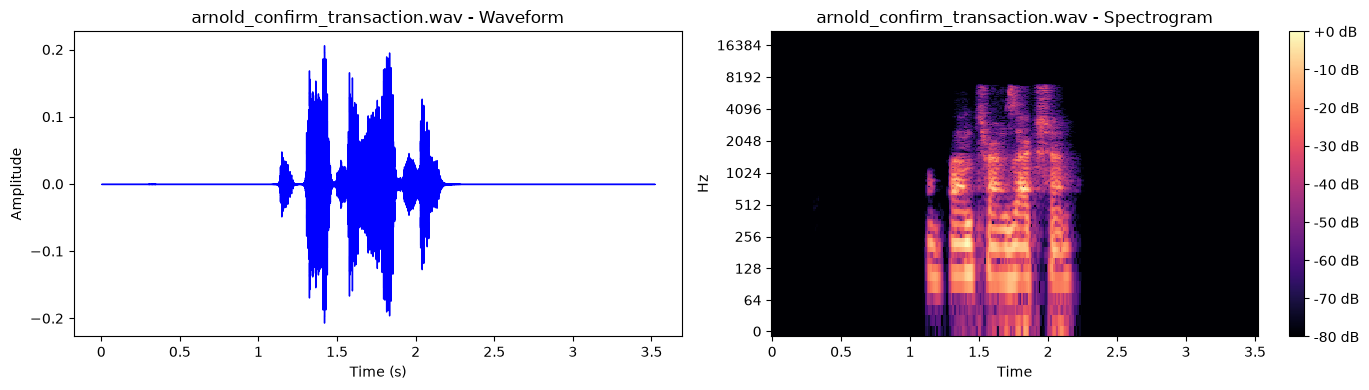

c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


Feature rows: none, pitch_shift, time_stretch, added_noise


,filename,member_name,phrase,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std
0,arnold_confirm_transaction.wav,arnold,confirm_transaction,none,-606.893616,120.984001,56.350830,91.431313,1.170918,34.488811,...,-0.863297,7.508655,1.117282,6.337730,2.669939,7.548357,1469.782779,3172.218243,0.009087,0.018232
1,arnold_confirm_transaction.wav,arnold,confirm_transaction,pitch_shift,-630.174438,122.284195,54.807610,87.682274,-0.955424,32.508568,...,-2.193791,7.834356,1.409555,8.335151,-2.947412,6.800631,2210.340801,4088.977404,0.006269,0.012659
2,arnold_confirm_transaction.wav,arnold,confirm_transaction,time_stretch,-646.713806,124.400002,58.997173,92.171249,1.139120,34.164673,...,-1.011103,8.143744,1.412511,6.348785,3.289596,8.428197,1940.272106,3808.455393,0.005820,0.011392
3,arnold_confirm_transaction.wav,arnold,confirm_transaction,added_noise,-331.045295,41.186658,16.097371,41.851663,6.588809,20.240637,...,-0.187887,5.595114,0.591324,6.227677,0.757035,5.321750,17694.059673,2210.756474,0.012819,0.016592


In [22]:
# Process Arnold - confirm transaction
arnold_confirm_transaction_features = process_audio_file(audio_files[0])
display(arnold_confirm_transaction_features)

**Arnold - confirm transaction:** This section loads and analyzes this recording only. The plots show its waveform and spectrogram; the table reports 13 MFCCs, spectral roll-off, and RMS energy for the original audio, pitch-shifted audio, time-stretched audio, and audio with added noise.

Processing arnold_yes_approve.wav | 16000 Hz | 2.82 seconds


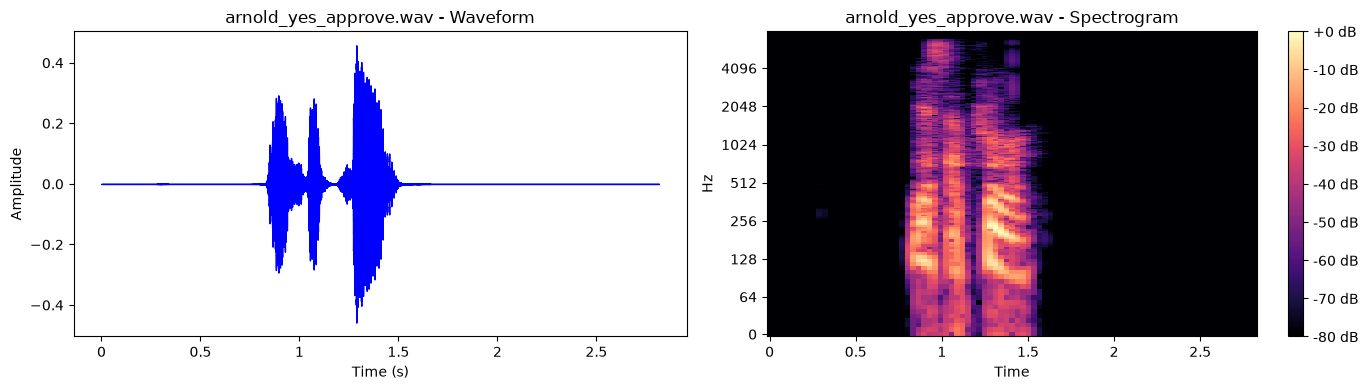

Feature rows: none, pitch_shift, time_stretch, added_noise


c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


,filename,member_name,phrase,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std
0,arnold_yes_approve.wav,arnold,yes_approve,none,-515.785950,148.267090,41.653450,73.948227,2.037823,21.794641,...,-6.596824,11.923340,-2.161373,6.573097,-4.324419,8.726550,1147.471910,1816.818753,0.020831,0.042553
1,arnold_yes_approve.wav,arnold,yes_approve,pitch_shift,-541.541260,164.715607,44.027950,72.117516,3.496882,18.382936,...,-6.332482,10.983595,-1.303630,5.900129,-4.235211,8.603265,2026.334270,2180.085115,0.015502,0.029623
2,arnold_yes_approve.wav,arnold,yes_approve,time_stretch,-570.806702,167.790009,49.046844,76.012314,4.363698,18.360552,...,-9.706306,15.305989,-2.972581,5.658697,-5.747701,9.874762,1840.300325,2129.803709,0.012568,0.023959
3,arnold_yes_approve.wav,arnold,yes_approve,added_noise,-274.905938,54.842411,19.212698,44.768184,6.519401,16.909931,...,-3.551967,9.055367,-2.265542,5.937632,-3.019933,6.238421,6036.429073,1645.685057,0.024438,0.040884


In [23]:
# Process Arnold - yes approve
arnold_yes_approve_features = process_audio_file(audio_files[1])
display(arnold_yes_approve_features)

**Arnold - yes approve:** This section loads and analyzes this recording only. The plots show its waveform and spectrogram; the table reports 13 MFCCs, spectral roll-off, and RMS energy for the original audio, pitch-shifted audio, time-stretched audio, and audio with added noise.

Processing Confirm transaction - Keane.wav | 22050 Hz | 2.82 seconds


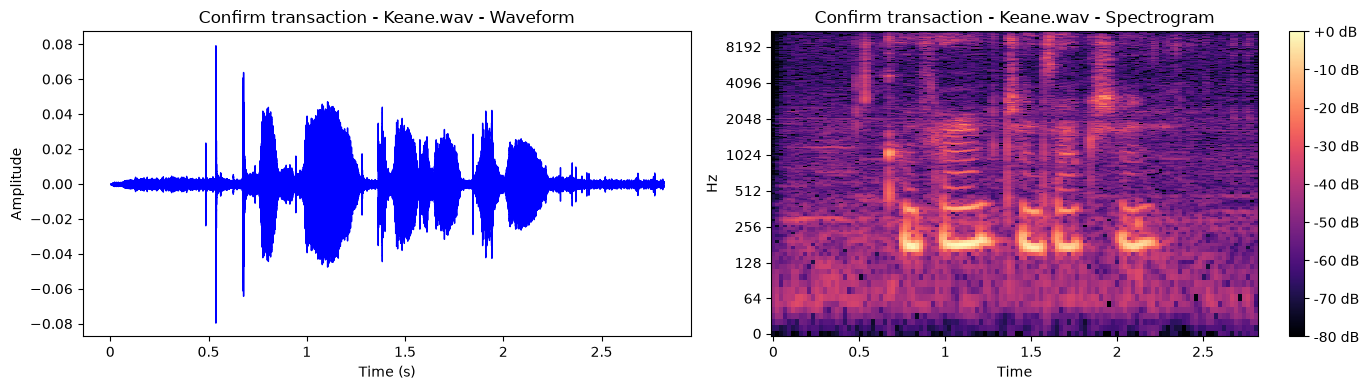

Feature rows: none, pitch_shift, time_stretch, added_noise


c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\numba\np\ufunc\dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


,filename,member_name,phrase,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std
0,Confirm transaction - Keane.wav,Keane,confirm_transaction,none,-430.401245,62.662079,51.646893,33.663624,6.566562,18.051981,...,-9.902123,9.929708,-6.860291,10.385299,-6.597787,6.577053,8262.748943,1048.548915,0.006817,0.006290
1,Confirm transaction - Keane.wav,Keane,confirm_transaction,pitch_shift,-466.472717,58.340939,50.660469,34.223995,2.029617,17.107798,...,-10.179771,11.235120,-5.962860,9.441904,-3.653107,7.244904,7702.885662,1707.134177,0.003969,0.003266
2,Confirm transaction - Keane.wav,Keane,confirm_transaction,time_stretch,-460.141113,59.758347,49.483738,32.133545,6.961240,17.650728,...,-10.711398,9.743785,-8.556082,10.874030,-7.579846,7.478703,8360.266113,997.934532,0.004540,0.003973
3,Confirm transaction - Keane.wav,Keane,confirm_transaction,added_noise,-300.150106,16.644738,7.957346,14.064955,4.982726,9.586295,...,-3.255773,6.394155,-4.605593,6.477417,-3.063329,5.522657,9194.501233,234.121525,0.009202,0.005111


In [24]:
# Process Keane - confirm transaction
confirm_transaction_keane_features = process_audio_file(audio_files[2])
display(confirm_transaction_keane_features)

**Keane - confirm transaction:** This section loads and analyzes this recording only. The plots show its waveform and spectrogram; the table reports 13 MFCCs, spectral roll-off, and RMS energy for the original audio, pitch-shifted audio, time-stretched audio, and audio with added noise.

Processing Crispin_confirm_transaction.wav | 44100 Hz | 3.65 seconds


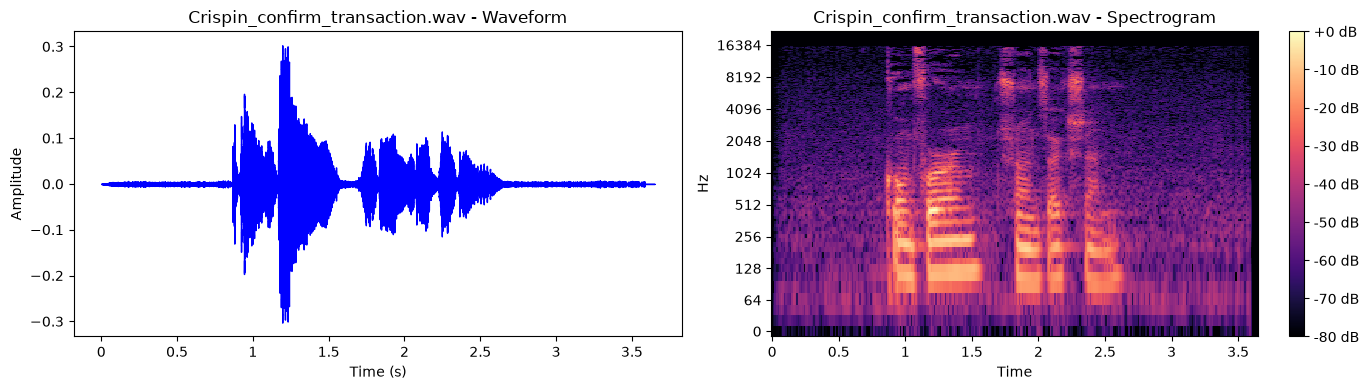

c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


Feature rows: none, pitch_shift, time_stretch, added_noise


,filename,member_name,phrase,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std
0,Crispin_confirm_transaction.wav,Crispin,confirm_transaction,none,-411.797821,78.432869,104.878159,46.589607,4.157314,23.696447,...,-10.603061,10.683345,6.307306,8.707747,-5.857646,7.034113,8135.585938,3473.405038,0.017269,0.022886
1,Crispin_confirm_transaction.wav,Crispin,confirm_transaction,pitch_shift,-442.744537,79.586830,97.060944,45.632374,8.783640,20.752806,...,-7.905004,8.436405,6.690819,10.319716,-9.194960,9.081388,9284.980469,3659.730651,0.011825,0.015018
2,Crispin_confirm_transaction.wav,Crispin,confirm_transaction,time_stretch,-449.178345,77.450623,103.328323,43.618690,4.884764,23.250242,...,-11.222826,11.074291,6.159380,9.016223,-6.150055,7.574247,8280.616838,3308.674714,0.011826,0.015856
3,Crispin_confirm_transaction.wav,Crispin,confirm_transaction,added_noise,-306.220512,40.970216,34.802352,40.595466,20.613363,23.157403,...,-3.495119,7.092883,0.852889,6.759398,-1.441953,5.845485,16778.945312,2639.996170,0.019436,0.021675


In [25]:
# Process Crispin - confirm transaction
crispin_confirm_transaction_features = process_audio_file(audio_files[3])
display(crispin_confirm_transaction_features)

**Crispin - confirm transaction:** This section loads and analyzes this recording only. The plots show its waveform and spectrogram; the table reports 13 MFCCs, spectral roll-off, and RMS energy for the original audio, pitch-shifted audio, time-stretched audio, and audio with added noise.

Processing Crispin_yes_approve.wav | 44100 Hz | 2.88 seconds


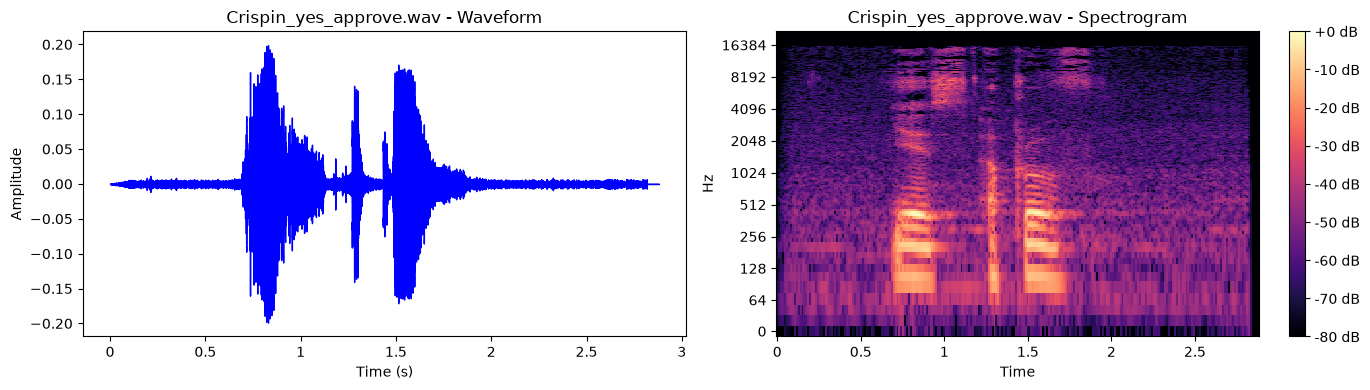

Feature rows: none, pitch_shift, time_stretch, added_noise


c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


,filename,member_name,phrase,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std
0,Crispin_yes_approve.wav,Crispin,yes_approve,none,-420.962555,72.718124,94.869057,39.091221,3.840469,14.394342,...,-9.046722,7.983727,3.414258,6.157618,-11.329412,10.953295,9206.438841,2971.290533,0.013934,0.023017
1,Crispin_yes_approve.wav,Crispin,yes_approve,pitch_shift,-450.364532,70.985085,85.678322,37.651661,12.638050,14.957366,...,-9.514494,8.882779,-1.082680,8.170337,-12.143755,11.514369,10393.272896,3114.601360,0.010403,0.017883
2,Crispin_yes_approve.wav,Crispin,yes_approve,time_stretch,-456.977997,69.160217,93.528954,38.114590,5.534287,15.153109,...,-8.858485,8.230048,3.763899,6.118519,-11.399290,11.261779,9317.895508,2781.015991,0.010454,0.017612
3,Crispin_yes_approve.wav,Crispin,yes_approve,added_noise,-313.321038,35.319623,27.147001,32.185267,18.433620,16.200190,...,-2.651738,5.302339,-1.665213,5.817753,-5.504527,8.279626,17136.192230,2298.590972,0.016349,0.021956


In [26]:
# Process Crispin - yes approve
crispin_yes_approve_features = process_audio_file(audio_files[4])
display(crispin_yes_approve_features)

**Crispin - yes approve:** This section loads and analyzes this recording only. The plots show its waveform and spectrogram; the table reports 13 MFCCs, spectral roll-off, and RMS energy for the original audio, pitch-shifted audio, time-stretched audio, and audio with added noise.

Processing Linda_confirm_transaction.wav | 22050 Hz | 1.97 seconds


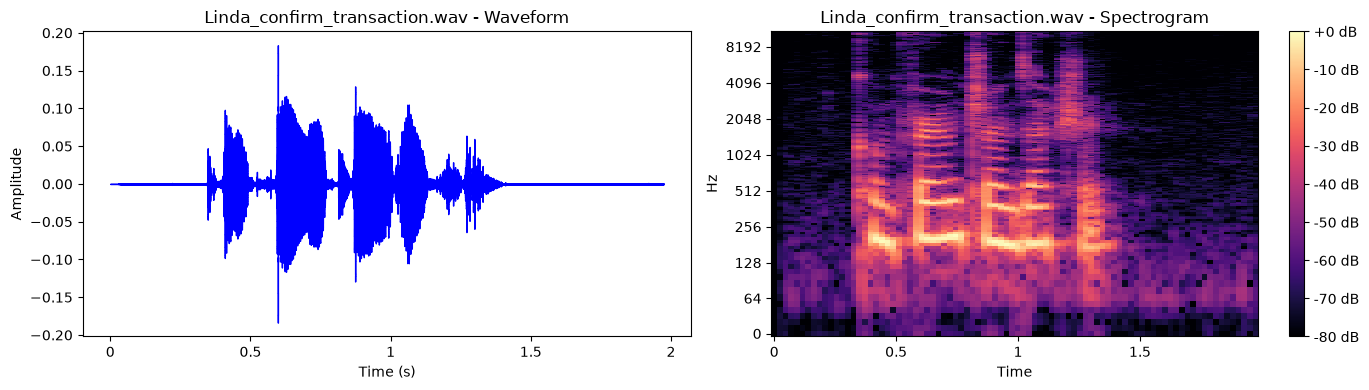

Feature rows: none, pitch_shift, time_stretch, added_noise


c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


,filename,member_name,phrase,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std
0,Linda_confirm_transaction.wav,Linda,confirm_transaction,none,-526.618530,140.868927,93.048126,54.227863,4.250154,27.613951,...,-3.750862,9.102750,-4.770883,9.555448,-2.146595,7.977129,4605.851994,2475.777312,0.013209,0.014907
1,Linda_confirm_transaction.wav,Linda,confirm_transaction,pitch_shift,-545.669006,146.108734,88.732094,50.198868,4.723968,24.972448,...,-3.660116,11.313307,-1.504521,7.442466,-2.095062,8.320693,4622.377475,2119.678193,0.009313,0.010454
2,Linda_confirm_transaction.wav,Linda,confirm_transaction,time_stretch,-540.814880,142.618484,89.048576,46.758686,7.309135,25.111805,...,-4.100703,8.312872,-4.997304,9.902581,-1.386336,6.083838,4577.551599,2195.379456,0.009309,0.010130
3,Linda_confirm_transaction.wav,Linda,confirm_transaction,added_noise,-292.611507,29.904375,19.414047,27.150379,9.406301,16.311866,...,-3.852913,5.827949,-3.133274,6.725126,-2.146316,5.041895,8681.761844,881.949257,0.015711,0.013210


In [27]:
# Process Linda - confirm transaction
linda_confirm_transaction_features = process_audio_file(audio_files[5])
display(linda_confirm_transaction_features)

**Linda - confirm transaction:** This section loads and analyzes this recording only. The plots show its waveform and spectrogram; the table reports 13 MFCCs, spectral roll-off, and RMS energy for the original audio, pitch-shifted audio, time-stretched audio, and audio with added noise.

Processing Linda_yes_approve.wav | 22050 Hz | 2.32 seconds


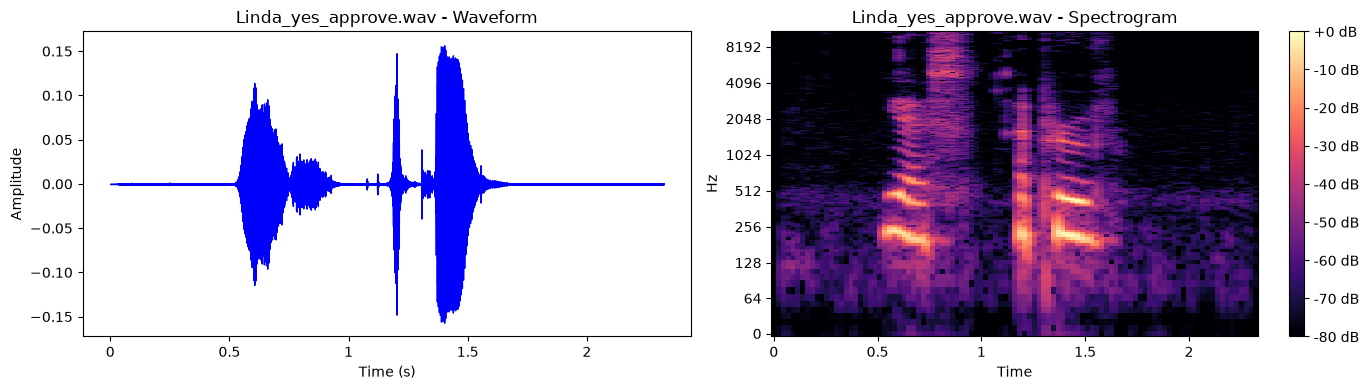

Feature rows: none, pitch_shift, time_stretch, added_noise


c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


,filename,member_name,phrase,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std
0,Linda_yes_approve.wav,Linda,yes_approve,none,-556.854980,119.026833,65.162552,56.290371,10.796749,20.738413,...,-2.283361,6.908078,-1.872730,8.941236,-3.927138,9.231485,5664.405022,2569.785730,0.009920,0.017085
1,Linda_yes_approve.wav,Linda,yes_approve,pitch_shift,-587.518066,124.524155,70.434906,54.665272,6.068223,22.605839,...,0.977842,8.286483,-2.828558,9.673196,-2.086433,8.850883,5317.315372,2236.740697,0.006971,0.010962
2,Linda_yes_approve.wav,Linda,yes_approve,time_stretch,-579.134705,123.164719,66.768364,54.443394,10.425561,18.775171,...,-2.757069,6.606081,-2.132488,8.766383,-5.311709,9.039227,5593.682651,2533.920322,0.006707,0.011159
3,Linda_yes_approve.wav,Linda,yes_approve,added_noise,-303.376185,23.529462,7.711937,21.862718,4.880213,8.685386,...,-1.547461,4.190982,-1.616887,4.423758,-2.198643,5.167417,8959.837900,793.561260,0.013108,0.015614


In [28]:
# Process Linda - yes approve
linda_yes_approve_features = process_audio_file(audio_files[6])
display(linda_yes_approve_features)

**Linda - yes approve:** This section loads and analyzes this recording only. The plots show its waveform and spectrogram; the table reports 13 MFCCs, spectral roll-off, and RMS energy for the original audio, pitch-shifted audio, time-stretched audio, and audio with added noise.

Processing Yes approve - Keane.wav | 22050 Hz | 2.65 seconds


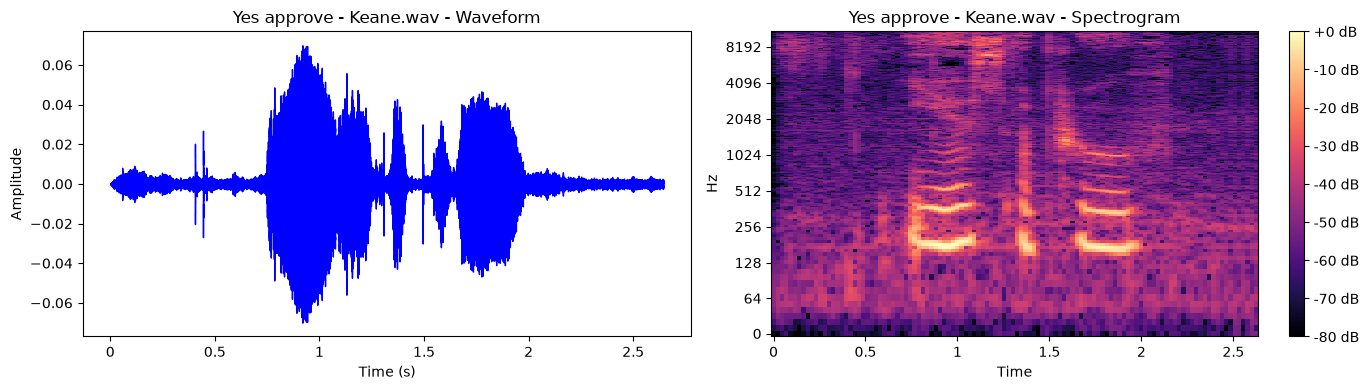

Feature rows: none, pitch_shift, time_stretch, added_noise


c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


,filename,member_name,phrase,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std
0,Yes approve - Keane.wav,Keane,yes_approve,none,-428.838898,61.022385,39.350452,38.553040,28.296705,24.829071,...,-11.438898,8.592254,-2.562231,7.093531,-4.427406,6.652584,8876.590769,823.775737,0.008137,0.008850
1,Yes approve - Keane.wav,Keane,yes_approve,pitch_shift,-467.994171,55.911015,43.583023,39.126102,24.017994,26.016531,...,-8.867888,6.942154,-1.700957,5.464100,-5.220367,6.688367,8067.584550,1964.501645,0.006101,0.007045
2,Yes approve - Keane.wav,Keane,yes_approve,time_stretch,-462.356476,59.759212,38.917377,37.488266,29.177229,24.125719,...,-10.944311,7.661152,-2.710611,6.517767,-4.763938,6.104176,8922.282715,784.988630,0.004636,0.004519
3,Yes approve - Keane.wav,Keane,yes_approve,added_noise,-299.130709,18.290138,7.496728,17.428413,10.521931,13.750182,...,-4.537805,6.335745,-3.311192,5.401051,-3.205575,4.021985,9243.221885,194.799687,0.010576,0.007545


In [29]:
# Process Keane - yes approve
yes_approve_keane_features = process_audio_file(audio_files[7])
display(yes_approve_keane_features)

**Keane - yes approve:** This section loads and analyzes this recording only. The plots show its waveform and spectrogram; the table reports 13 MFCCs, spectral roll-off, and RMS energy for the original audio, pitch-shifted audio, time-stretched audio, and audio with added noise.

In [31]:
# 6. SAVE THE COMBINED FEATURE DATASET

audio_df = pd.concat([arnold_confirm_transaction_features, arnold_yes_approve_features, confirm_transaction_keane_features, crispin_confirm_transaction_features, crispin_yes_approve_features, linda_confirm_transaction_features, linda_yes_approve_features, yes_approve_keane_features], ignore_index=True)
output_csv = "audio_features.csv"
audio_df.to_csv(output_csv, index=False)
print(f"Saved {len(audio_df)} feature rows from {audio_df['filename'].nunique()} recordings to '{output_csv}'.")


Saved 32 feature rows from 8 recordings to 'audio_features.csv'.
